# AAVAIL Revenue Forecast | 01 - Exploratory Data Analysis (EDA)

**Business question:** AAVAIL management wants to predict the revenue for the
following month, for any country or for all countries combined, so staff can
plan resources.

**Data:** monthly JSON invoice files in `data/cs-train`. Ingestion is automated
by `cslib.fetch_data()` (raw transactions) and `cslib.fetch_ts()` (daily time
series per country). This notebook uses those same functions.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
FIG_DIR = os.path.join('..', 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
%matplotlib inline

## 1. Ingest the data

In [2]:
from cslib import fetch_data, fetch_ts, DATA_DIR
df = fetch_data(DATA_DIR)
print(df.shape)
print('date range:', df.invoice_date.min().date(), 'to', df.invoice_date.max().date())
print('countries:', df.country.nunique())
df.head()

(74207, 10)
date range: 2017-11-28 to 2019-07-31
countries: 19


,country,customer_id,day,invoice,month,price,stream_id,times_viewed,year,invoice_date
0,Norway,13208.0,28,489001,11,3.01,22869,19,2017,2017-11-28
1,France,13726.0,28,489028,11,1.69,23252,18,2017,2017-11-28
2,France,13726.0,28,489028,11,2.04,20399,18,2017,2017-11-28
3,France,13726.0,28,489028,11,0.90,22036,2,2017,2017-11-28
4,United Kingdom,NaN,28,489029,11,5.71,23535,9,2017,2017-11-28


## 2. Data quality: missing values and summary statistics

In [3]:
missing = df.isnull().mean().mul(100).round(2).rename('% missing')
display(missing.to_frame())
df[['price', 'times_viewed']].describe()

,% missing
country,0.00
customer_id,20.13
day,0.00
invoice,0.00
month,0.00
price,0.00
stream_id,0.00
times_viewed,0.00
year,0.00
invoice_date,0.00


,price,times_viewed
count,74207.000000,74207.000000
mean,3.769427,12.502581
std,3.656977,6.926683
min,0.100000,1.000000
25%,1.590000,6.000000
50%,2.720000,13.000000
75%,4.660000,18.000000
max,149.270000,24.000000


## 3. Revenue over time (monthly)

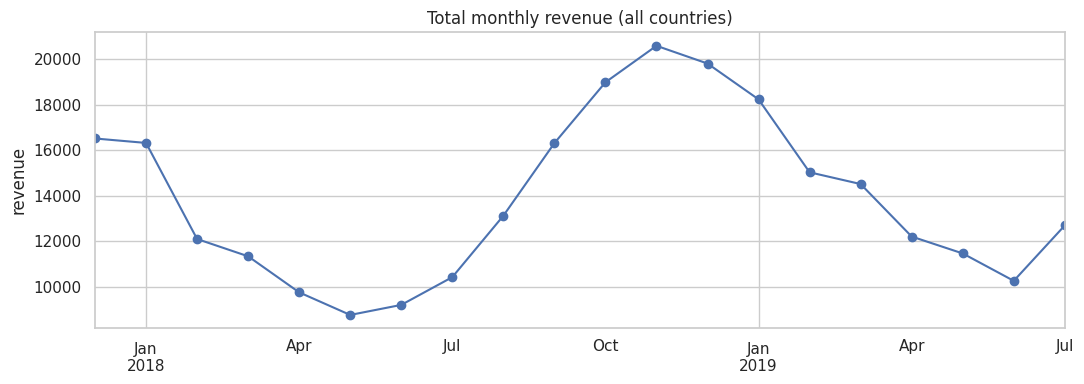

In [4]:
monthly = df.set_index('invoice_date')['price'].resample('MS').sum()
days_per_month = df.groupby(df.invoice_date.dt.to_period('M')).invoice_date.nunique()
monthly = monthly[days_per_month.values >= 20]  # drop partial months at the edges
fig, ax = plt.subplots(figsize=(11, 4))
monthly.plot(ax=ax, marker='o')
ax.set_title('Total monthly revenue (all countries)')
ax.set_ylabel('revenue'); ax.set_xlabel('')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_monthly_revenue.png'), dpi=120)
plt.show()

## 4. Top 10 countries by revenue

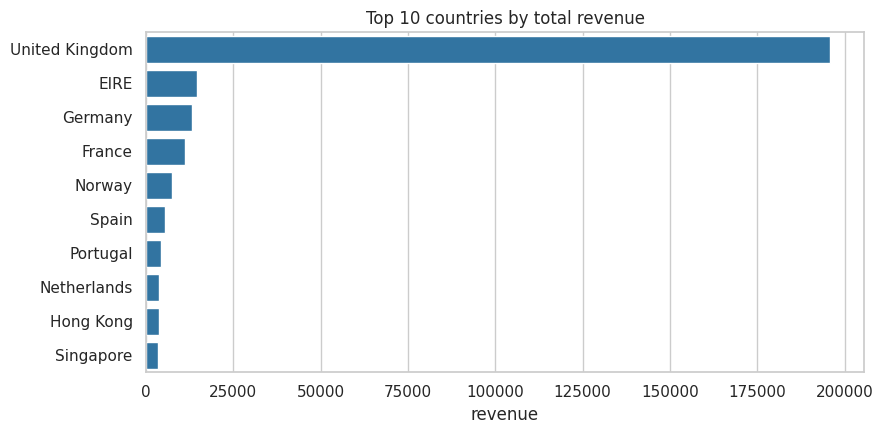

Top 10 countries = 93.9% of revenue


In [5]:
by_country = df.groupby('country')['price'].sum().sort_values(ascending=False)
top10 = by_country.head(10)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=top10.values, y=top10.index, ax=ax, color='tab:blue')
ax.set_title('Top 10 countries by total revenue'); ax.set_xlabel('revenue'); ax.set_ylabel('')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_top10_countries.png'), dpi=120)
plt.show()
print(f"Top 10 countries = {top10.sum() / by_country.sum():.1%} of revenue")

## 5. Daily revenue and 30-day rolling average for the top countries

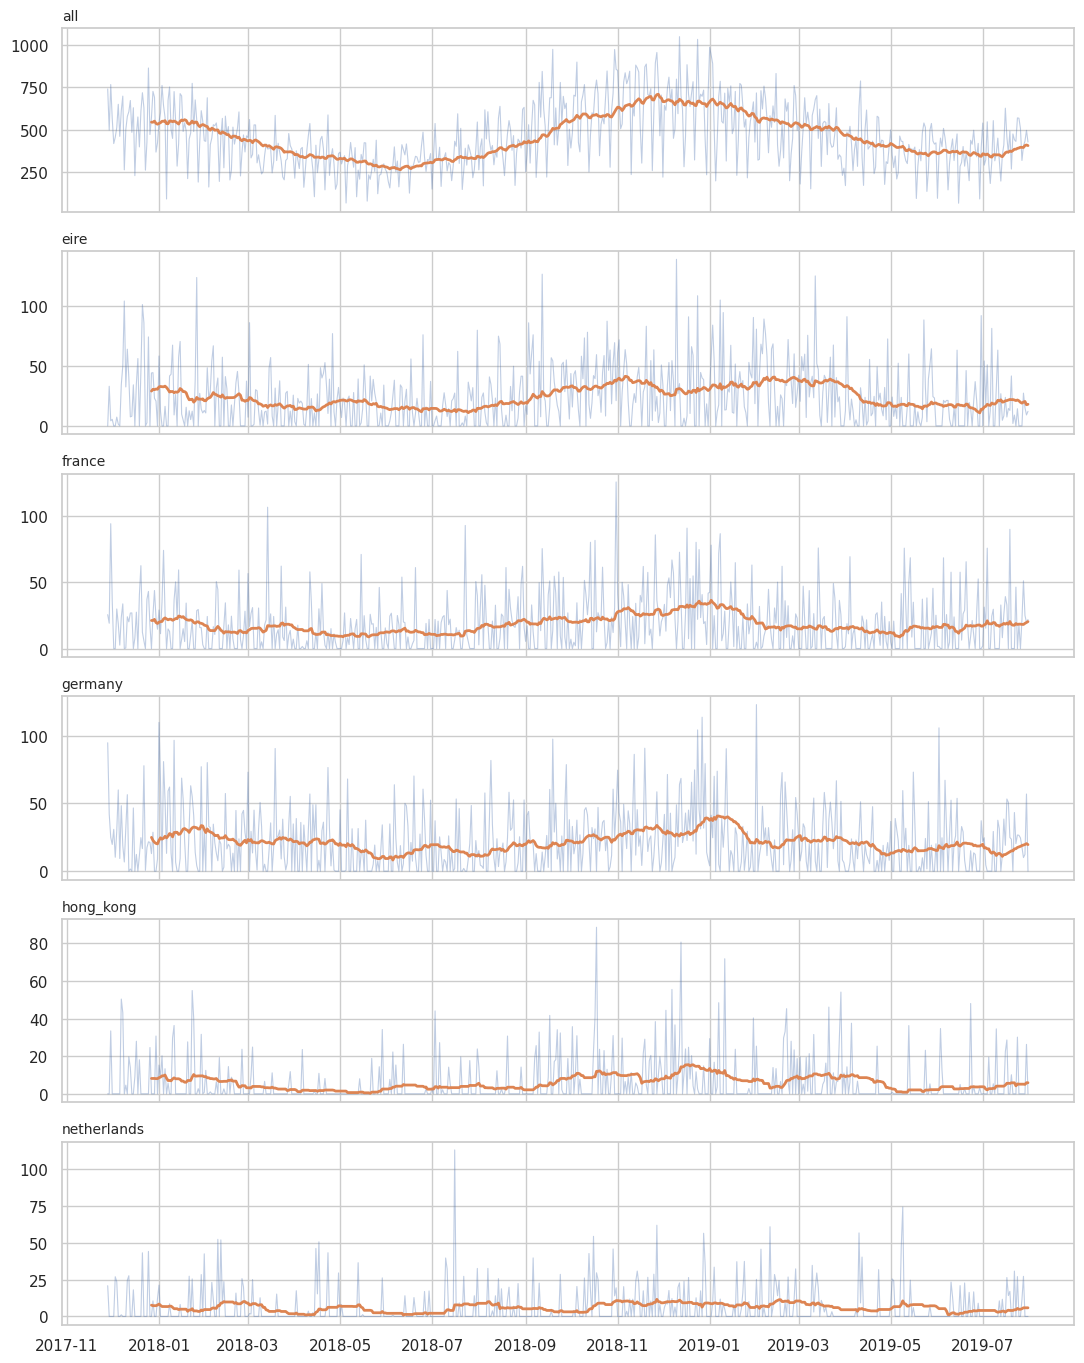

In [6]:
ts = fetch_ts(DATA_DIR)
keys = ['all'] + [k for k in ts if k != 'all'][:5]
fig, axes = plt.subplots(len(keys), 1, figsize=(11, 2.3 * len(keys)), sharex=True)
for ax, key in zip(axes, keys):
    s = ts[key].set_index('date')['revenue']
    ax.plot(s.index, s.values, alpha=0.35, lw=0.8)
    ax.plot(s.index, s.rolling(30).mean(), lw=2)
    ax.set_title(key, loc='left', fontsize=10)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_daily_revenue_by_country.png'), dpi=120)
plt.show()

## 6. Weekly pattern

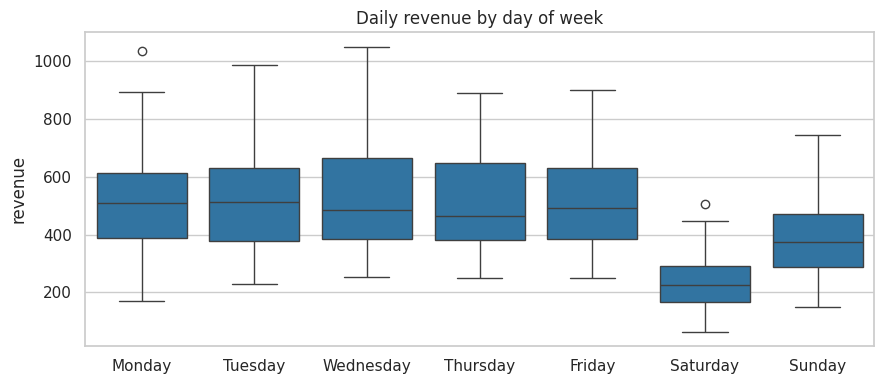

In [7]:
daily = ts['all'].copy()
daily['weekday'] = daily['date'].dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=daily, x='weekday', y='revenue', order=order, ax=ax, color='tab:blue')
ax.set_title('Daily revenue by day of week'); ax.set_xlabel('')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_weekday.png'), dpi=120)
plt.show()

## 7. Relationships between daily features

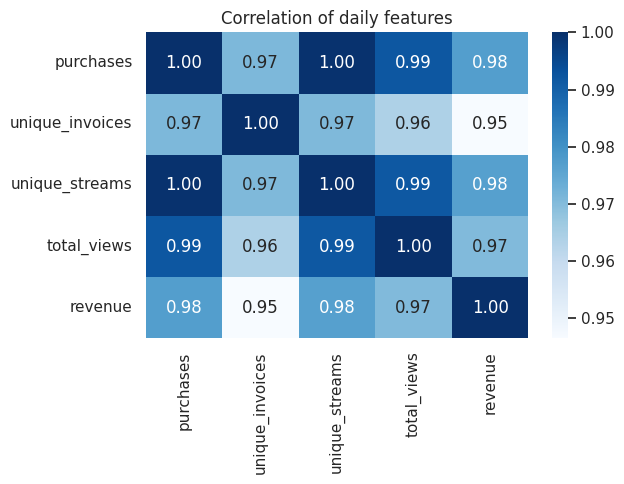

In [8]:
corr = ts['all'][['purchases','unique_invoices','unique_streams','total_views','revenue']].corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set_title('Correlation of daily features')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_correlation.png'), dpi=120)
plt.show()

## 8. Distribution of daily revenue

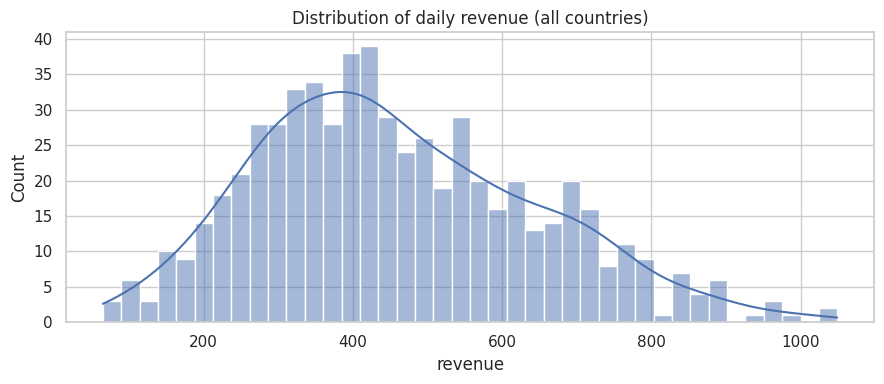

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(ts['all']['revenue'], bins=40, kde=True, ax=ax)
ax.set_title('Distribution of daily revenue (all countries)')
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'eda_revenue_distribution.png'), dpi=120)
plt.show()

## 9. Findings

* Revenue is concentrated in a few countries (the United Kingdom dominates), so
  the API serves models for the **top 10 countries plus all countries combined**.
* Revenue has a clear **seasonal pattern** (peaks toward the end of the year)
  and a **weekly pattern** (lower at weekends), so features based on recent
  revenue windows and on the same period last year are useful.
* The number of invoices, streams and views move closely with revenue, so
  recent activity is included as a feature.
* Daily revenue is noisy; predicting the **sum over the next 30 days** smooths
  this out and matches the business question (next month's revenue).

**Hypotheses to test in modelling:** a non-linear model using recent revenue
windows will beat a naive baseline (predicting the average), and the advantage
will be largest for the countries with the most data.